> Run from the cloned repo (Anaconda Jupyter on Windows/Linux/macOS, or Colab after cloning https://github.com/Rishabh-bgp/multi-agent-turbine-fleet-chief-of-staff). Install dependencies once with `%pip install -r requirements.txt` (or `%pip install -r ../requirements.txt` from `notebooks/`). The data cell finds the committed synthetic CSV, downloads it from GitHub, or regenerates it.

# Walkthrough: forecasting agent + one multi-agent planning cycle
Simplified version of `src/simulate.py`. Agents are deterministic Python (no LLM). Reimplementation; numbers will differ from the paper.

In [1]:
import os, sys, urllib.request
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '2')
# repo root = folder containing src/ (works from notebooks/ or repo root, Windows/Linux/Colab)
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src').is_dir()), Path.cwd())
sys.path.insert(0, str(ROOT))
REPO = 'multi-agent-turbine-fleet-chief-of-staff'

def find_csv(name):
    """../data -> data -> GitHub raw URL -> regenerate with the seeded generator."""
    for p in [Path.cwd().parent / 'data' / name, Path.cwd() / 'data' / name, ROOT / 'data' / name]:
        if p.exists(): return p
    out = ROOT / 'data' / name; out.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/Rishabh-bgp/{REPO}/main/data/{name}', out); return out
    except Exception as e:
        print('download failed, regenerating synthetic data:', e)
    if name == 'synthetic_sites.csv':
        from src.sites import synthetic_sites; synthetic_sites(n_hours=24 * 60, seed=0).to_csv(out, index=False)
    else:
        from src.data import synthetic_scada; d = synthetic_scada(24 * 120, seed=0); d.index.name = 'timestamp'; d.to_csv(out)
    return out

import numpy as np, torch, matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(2)
print('repo root:', ROOT)

repo root: multi-agent-turbine-fleet-chief-of-staff


## 1. Load the committed synthetic SCADA-style CSV
`data/synthetic_scada.csv` is **synthetic** (seeded generator `scripts/make_synthetic.py`), not the confidential original SCADA data.

In [2]:
from src.data import load_scada_csv, add_features, make_windows, chrono_split, Scaler
from src.metrics import regression_metrics
raw = load_scada_csv(find_csv('synthetic_scada.csv'))
raw.head()

,wind_speed,wind_direction,temperature,pressure,humidity,power
timestamp,,,,,,
2018-01-01 00:00:00,5.737794,223.408447,23.940016,1008.144888,79.291828,181.450999
2018-01-01 01:00:00,5.311578,203.414522,25.093541,1008.083422,78.237979,125.660019
2018-01-01 02:00:00,6.098380,187.419159,23.755674,1008.513628,75.607545,246.256732
2018-01-01 03:00:00,5.912926,207.694372,24.992387,1007.578456,73.548041,210.616083
2018-01-01 04:00:00,5.666016,211.785966,24.673154,1008.536566,75.529499,170.637901


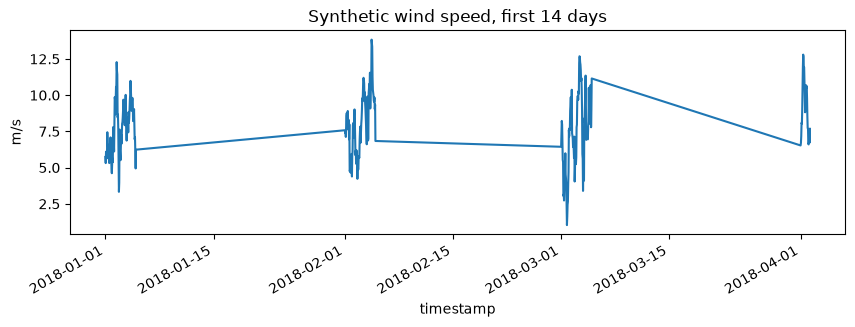

In [3]:
raw['wind_speed'].iloc[:24*14].plot(figsize=(10,3), title='Synthetic wind speed, first 14 days'); plt.ylabel('m/s'); plt.show()

## 2. Train the forecasting agent's small CNN-BiLSTM-Attention briefly

In [4]:
from src.trainutil import fit, predict
from src.forecaster import CNNBiLSTMAttention, power_curve
df = add_features(raw); X, y = make_windows(df, lookback=24); wi = list(df.columns).index('wind_speed')
tr, va, te = chrono_split(len(X)); sc = Scaler().fit(X[tr]); Xs = sc.transform(X).astype('float32'); ym, ys = y[tr].mean(), y[tr].std()
m = fit(CNNBiLSTMAttention(X.shape[2]), Xs[tr], ((y[tr]-ym)/ys).astype('float32'), Xs[va], ((y[va]-ym)/ys).astype('float32'), epochs=3)
pred = predict(m, Xs[te])*ys + ym
print('forecast   ', regression_metrics(y[te], pred))
print('persistence', regression_metrics(y[te], X[te][:, -1, wi]))

forecast    {'MAE': 1.7754871275689867, 'RMSE': 2.27018211923799, 'MAPE_%': 22.494898491410513, 'R2': 0.08685976302771214}
persistence {'MAE': 0.7786463048723009, 'RMSE': 1.0788346983033934, 'MAPE_%': 10.084407356304313, 'R2': 0.7937823207879058}


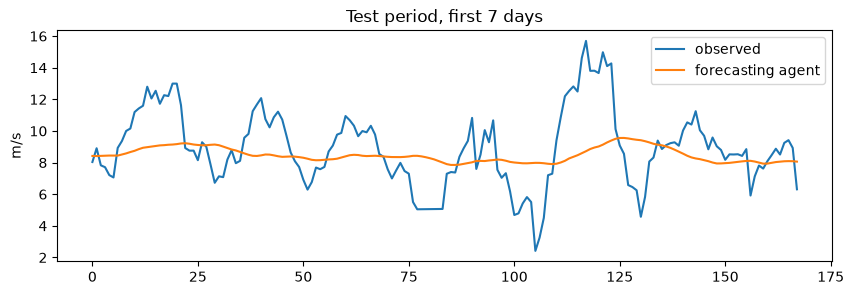

In [5]:
plt.figure(figsize=(10,3)); plt.plot(y[te][:168], label='observed'); plt.plot(pred[:168], label='forecasting agent'); plt.legend(); plt.ylabel('m/s'); plt.title('Test period, first 7 days'); plt.show()

## 3. One orchestrated cycle for a 4-turbine fleet (turbine 2 is degrading)
The orchestrator runs forecasting → SCADA monitor → maintenance → grid/trading → human approval gate.

In [6]:
from src.agents.orchestrator import OrchestratorAgent
forecaster = lambda Wd: predict(m, sc.transform(Wd).astype('float32'))*ys + ym
orch = OrchestratorAgent(forecaster, power_curve, approver=lambda b: True)
win = np.stack([X[te][0]]*4); vib = np.array([2.5,3.0,7.5,2.8]); temp = np.array([58,60,84,57.])
hist = np.random.default_rng(0).normal([3,58],[0.5,2],(24,4,2))
bundle, ok = orch.cycle(win, hist, np.stack([vib,temp],-1), vib, temp, grid_limit_kw=5000)
print('approved:', ok); bundle['work_orders'], bundle['dispatch']

approved: True


([{'turbine': 2,
   'risk': 1.1,
   'action': 'stop_and_inspect',
   'evidence': ['Gearbox oil temperature above 80 C for more than 2 hours: reduce power set-point and schedule an inspection.']}],
 {'setpoints_kw': [436.9, 436.9, 0.0, 436.9],
  'curtail_factor': 1.0,
  'scheduled_kw': 1310.6132532305296})